# Demo notebook

This notebook runs and compares this project's methods (AMD, MD, Variational (1)) on three synthetic datasets — Gaussian mixture, sphere, ring Gaussians (see the manuscript for the description of the datesets or see `src.data_construction.py` for code used to generate the data) — and on the instability example (a reconstruction of the Houry et al 2026 Figure 7). We choose to only present the results for the AMD and the Variational (1) method since the Variational (L) and Accelerated variational (L) take a large number of iterations to converge and hence would make this notebook more computationally expensive.

If you want to rum the Variational (L) and Accelerated variational (L) you can just change the  `methods=["amd", "dual_variational"]` to  `methods=["amd", "dual_variational", "variational", "accelerated]`. If you want to try on one example choose `sphere` as it will run for the shortest time. You can also lower the number of maximum iterations to make it  terminate quicker.

**How to use it:** run the cells top to bottom. Each dataset has three cells in a row: **visualize** the point clouds, **run** the methods, **plot** the results (primal/dual stationarity and objective). To change a setting (regularization, iteration budget, tolerances, ...), edit the `algorithm_overrides` dict in that dataset's run cell, using the same key names as in `configs/<dataset>.yaml`.

Install the packages listed in `requirements.txt` before running.

In [1]:
import sys
import warnings
from pathlib import Path

REPO_ROOT = Path.cwd()
sys.path.insert(0, str(REPO_ROOT))

import numpy as np
import matplotlib.pyplot as plt

from src.dataset_construction import make_point_clouds, example_point_clouds
from src.utilis import load_config, prepare_experiment, aggregate_runs
from src.plots import project_for_plotting, plot_transport, draw_stationarity, draw_objective, draw_lag2
from src.multi_seed_setup import run_method_sweep, run_methods_on_problem, selected_jobs
from src.cost_construction import lag2_frobenius

%matplotlib inline

def _path_free_warning_format(message, category, filename, lineno, line=None):
    return f"{category.__name__}: {message}\n"
warnings.formatwarning = _path_free_warning_format

In [2]:
def show_overlay(aggregate):
    groups = [(kind, [r for r in aggregate if r.get("stationarity_kind", "primal") == kind])
              for kind in ("primal", "dual")]
    groups = [(kind, results) for kind, results in groups if results]
    has_lag2 = any("lag2_mean" in r for r in aggregate)
    n_panels = len(groups) + 1 + (1 if has_lag2 else 0)
    fig, axes = plt.subplots(1, n_panels, figsize=(7 * n_panels, 5), squeeze=False)
    for axis, (kind, results) in zip(axes[0], groups):
        draw_stationarity(axis, results, kind)
    draw_objective(axes[0][len(groups)], aggregate)
    if has_lag2:
        draw_lag2(axes[0][len(groups) + 1], aggregate)

    seen = {}
    for axis in axes[0]:
        for handle, label in zip(*axis.get_legend_handles_labels()):
            seen.setdefault(label, handle)

    def annotation_rank(label):
        if label == "O(1/j)":
            return 1
        if label.startswith("Stopping tolerance"):
            return 2
        if label == "Running min":
            return 3
        return 0

    labels = sorted(seen, key=annotation_rank)
    handles = [seen[label] for label in labels]
    fig.legend(handles, labels, loc="center left", bbox_to_anchor=(1.0, 0.5))
    fig.tight_layout()
    plt.show()

In [3]:
def show_transport_snapshots(metrics, arrays, x, y):
    """One row per method, coupling snapshots at selected iterations. Mirrors
    src.plots.save_transport_snapshots (t=.. above each column, method name to the
    left of each row), but shows inline instead of saving to disk."""
    rows = []
    for result in metrics:
        key = result["method"].replace(".", "p")
        couplings = arrays.get(f"couplings_{key}")
        if couplings is not None and len(couplings) >= 1:
            rows.append((result.get("label", result["method"]), np.asarray(couplings)))
    if not rows:
        print("No recorded coupling history.")
        return
    n_cols = 6
    fig, axes = plt.subplots(len(rows), n_cols, figsize=(3.2 * n_cols, 2.6 * len(rows)), squeeze=False)
    for row, (label, couplings) in enumerate(rows):
        last = len(couplings) - 1
        selected = sorted({s for s in (0, 1, 2, last - 2, last - 1, last) if 0 <= s <= last})
        for col, step in enumerate(selected):
            plot_transport(axes[row, col], x, y, couplings[step])
            axes[row, col].set_title(f"t={step}")
        for col in range(len(selected), n_cols):
            axes[row, col].axis("off")
        axes[row, 0].text(-0.15, 0.5, label, transform=axes[row, 0].transAxes,
                          ha="right", va="center", rotation=0)
    fig.tight_layout()
    plt.show()

## Notebook helpers

Two small functions set up the pattern used by every dataset section below (visualize → run → plot):
- `visualize_point_clouds(config_name, ...)` loads `configs/<config_name>.yaml`, samples its point clouds, shows them, and returns the config for the next cell.
- `run_dataset(config, methods, ...)` runs the selected `methods` over `num_seeds` seeds and returns the aggregated results.

The plotting cell then just calls `show_overlay(aggregate)`, defined above.

In [4]:
def visualize_point_clouds(config_name, viz_seed=0, n_points_x=None, n_points_y=None):
    """Load configs/<config_name>.yaml, sample its point clouds and show them.
    Returns the loaded config (with viz_seed set) for the run cell to reuse."""
    config = load_config(REPO_ROOT / "configs" / f"{config_name}.yaml")
    config["experiment"]["seed"] = viz_seed
    if config_name == "gaussian_mixture":
        if n_points_x is not None:
            config["data"]["n_points_x"] = int(n_points_x)
        if n_points_y is not None:
            config["data"]["n_points_y"] = int(n_points_y)

    clouds = make_point_clouds(config)
    x, y = clouds["x"], clouds["y"]

    fig = plt.figure(figsize=(5, 5))
    if x.shape[1] == 3 and y.shape[1] == 3:
        axis = fig.add_subplot(111, projection="3d")
        polar = np.linspace(0.0, np.pi, 15)
        azimuth = np.linspace(0.0, 2.0 * np.pi, 30)
        sphere_x = np.outer(np.cos(azimuth), np.sin(polar))
        sphere_y = np.outer(np.sin(azimuth), np.sin(polar))
        sphere_z = np.outer(np.ones_like(azimuth), np.cos(polar))
        axis.plot_wireframe(sphere_x, sphere_y, sphere_z, color="lightgray", linewidth=0.4, alpha=0.5)
        axis.scatter(x[:, 0], x[:, 1], x[:, 2], s=14, alpha=0.7, label="X")
        axis.scatter(y[:, 0], y[:, 1], y[:, 2], s=14, alpha=0.7, label="Y")
        axis.view_init(elev=20, azim=45)
        if hasattr(axis, "set_box_aspect"):
            axis.set_box_aspect((1, 1, 1))
    else:
        axis = fig.add_subplot(111)
        x2d, y2d = project_for_plotting(x), project_for_plotting(y)
        axis.scatter(*x2d.T, s=14, alpha=0.7, label="X")
        axis.scatter(*y2d.T, s=14, alpha=0.7, label="Y")
        axis.set_aspect("equal", adjustable="box")
    #axis.set_title(f"{config_name} (seed {viz_seed})")
    axis.legend(loc="upper right")
    plt.show()

    return config


def run_dataset(config, methods, sinkhorn_method="sinkhorn", num_seeds=1, seeds=None, algorithm_overrides=None):
    """Run `methods` on `config`. By default sweeps seeds 0..num_seeds-1; pass an
    explicit `seeds` list (e.g. seeds=[42]) to run one or more chosen seeds instead,
    ignoring num_seeds."""
    config["algorithm"]["methods"] = methods
    config["algorithm"]["sinkhorn_method"] = sinkhorn_method
    config["algorithm"].update(algorithm_overrides or {})

    seeds = list(seeds) if seeds is not None else list(range(num_seeds))
    runs = []
    for seed in seeds:
        seed_config = {**config, "experiment": {**config["experiment"], "seed": seed}}
        print(f"Running seed {seed}")
        results, _arrays = run_method_sweep(seed_config)
        runs.append({"seed": seed, "results": results})

    aggregate, _aggregate_arrays = aggregate_runs(runs, seeds)
    return aggregate

If you want to change a hyperparameter (regularization, iteration budget, tolerances, ...), edit the `algorithm_overrides` dict in that section's run cell, using the same key names as in the corresponding `configs/*.yaml` file.

## Gaussian mixture

In order to ensure runing the notebook does not take too long, the number of points is set to 100, while the figures in the manuscript use $N_x$ = $N_y$ = 1000. All the other hyperparameters match the manuscript via `configs/gaussian_mixture.yaml`.

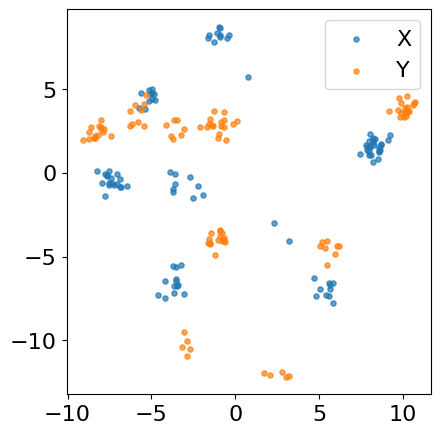

In [5]:
gaussian_mixture_config = visualize_point_clouds("gaussian_mixture", n_points_x=100, n_points_y=100)

In [6]:
gaussian_mixture_aggregate = run_dataset(
    gaussian_mixture_config,
    methods=[ "amd", "dual_variational"],
    sinkhorn_method="sinkhorn",
    num_seeds=1,
    algorithm_overrides={},  # e.g. {"reg": 0.02, "max_iterations": 5000}
)

Running seed 0
  Running AMD (alpha=0.1)
Iteration 0, Stationarity: 1.3411840931342947
Iteration 50, Stationarity: 0.0007020788269723982
Iteration 100, Stationarity: 1.0911148515248611e-05
Iteration 150, Stationarity: 9.408858499184579e-06
Iteration 200, Stationarity: 5.19253916055012e-06
Iteration 238, Stationarity: 9.671592956977994e-07
  AMD (alpha=0.1): outer tolerance reached (3.38s)
  Running AMD (alpha=0.5)
Iteration 0, Stationarity: 1.3411840931342947
Iteration 47, Stationarity: 8.079464512848276e-07
  AMD (alpha=0.5): outer tolerance reached (0.83s)
  Running AMD (alpha=0.9)
Iteration 0, Stationarity: 1.3411840931342947
Iteration 27, Stationarity: 7.069698355312209e-07
  AMD (alpha=0.9): outer tolerance reached (0.44s)
  Running MD (alpha=1)
Iteration 0, Stationarity: 1.3411840931342947
Iteration 16, Stationarity: 7.312068526095527e-07
  MD (alpha=1): outer tolerance reached (0.29s)
  Running Variational (1)
Iteration 0, Squared L2 gradient: 0.985003103099341
Iteration 26, Squ

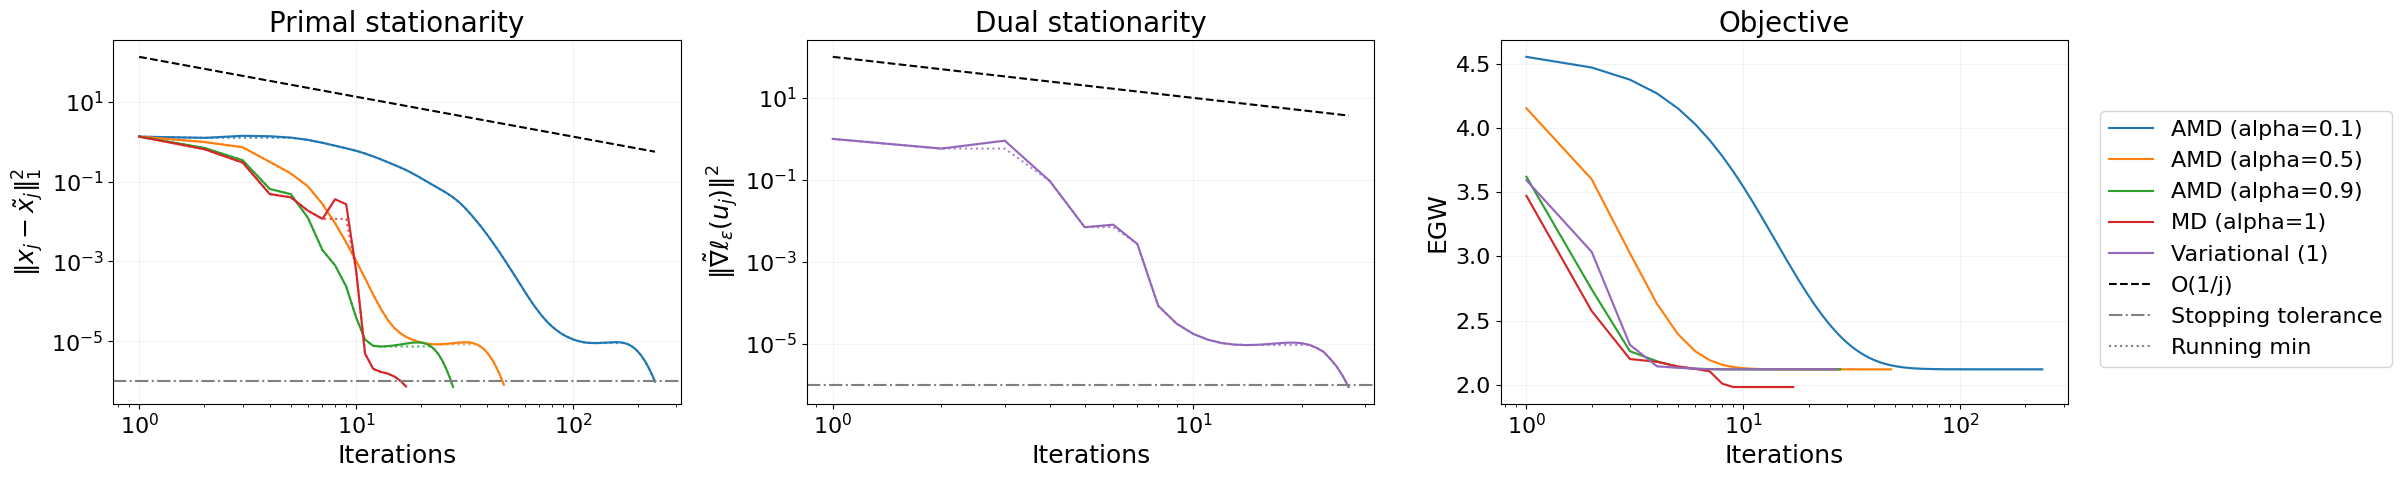

In [7]:
show_overlay(gaussian_mixture_aggregate)

## Sphere

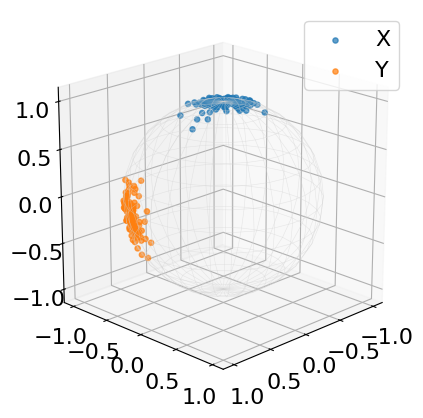

In [8]:
sphere_config = visualize_point_clouds("sphere")

In [9]:
sphere_aggregate = run_dataset(
    sphere_config,
    methods=["amd", "dual_variational"],
    sinkhorn_method="sinkhorn",
    num_seeds=1,
    algorithm_overrides={},  # e.g. {"reg": 0.02, "max_iterations": 5000}
)

Running seed 0
  Running AMD (alpha=0.1)
Iteration 0, Stationarity: 0.4647950285225856
Iteration 50, Stationarity: 0.011733290203805487
Iteration 100, Stationarity: 5.2174632648602355e-05
Iteration 132, Stationarity: 9.283415945138952e-07
  AMD (alpha=0.1): outer tolerance reached (0.39s)
  Running AMD (alpha=0.5)
Iteration 0, Stationarity: 0.4647950285225856
Iteration 26, Stationarity: 6.095863180356156e-07
  AMD (alpha=0.5): outer tolerance reached (0.08s)
  Running AMD (alpha=0.9)
Iteration 0, Stationarity: 0.4647950285225856
Iteration 14, Stationarity: 3.835817249020787e-07
  AMD (alpha=0.9): outer tolerance reached (0.05s)
  Running MD (alpha=1)
Iteration 0, Stationarity: 0.4647950285225856
Iteration 12, Stationarity: 8.238736604614163e-07
  MD (alpha=1): outer tolerance reached (0.04s)
  Running Variational (1)
Iteration 0, Squared L2 gradient: 0.0044976280606558216
Iteration 10, Squared L2 gradient: 4.5545503719844714e-07
  Variational (1): outer tolerance reached (0.09s)


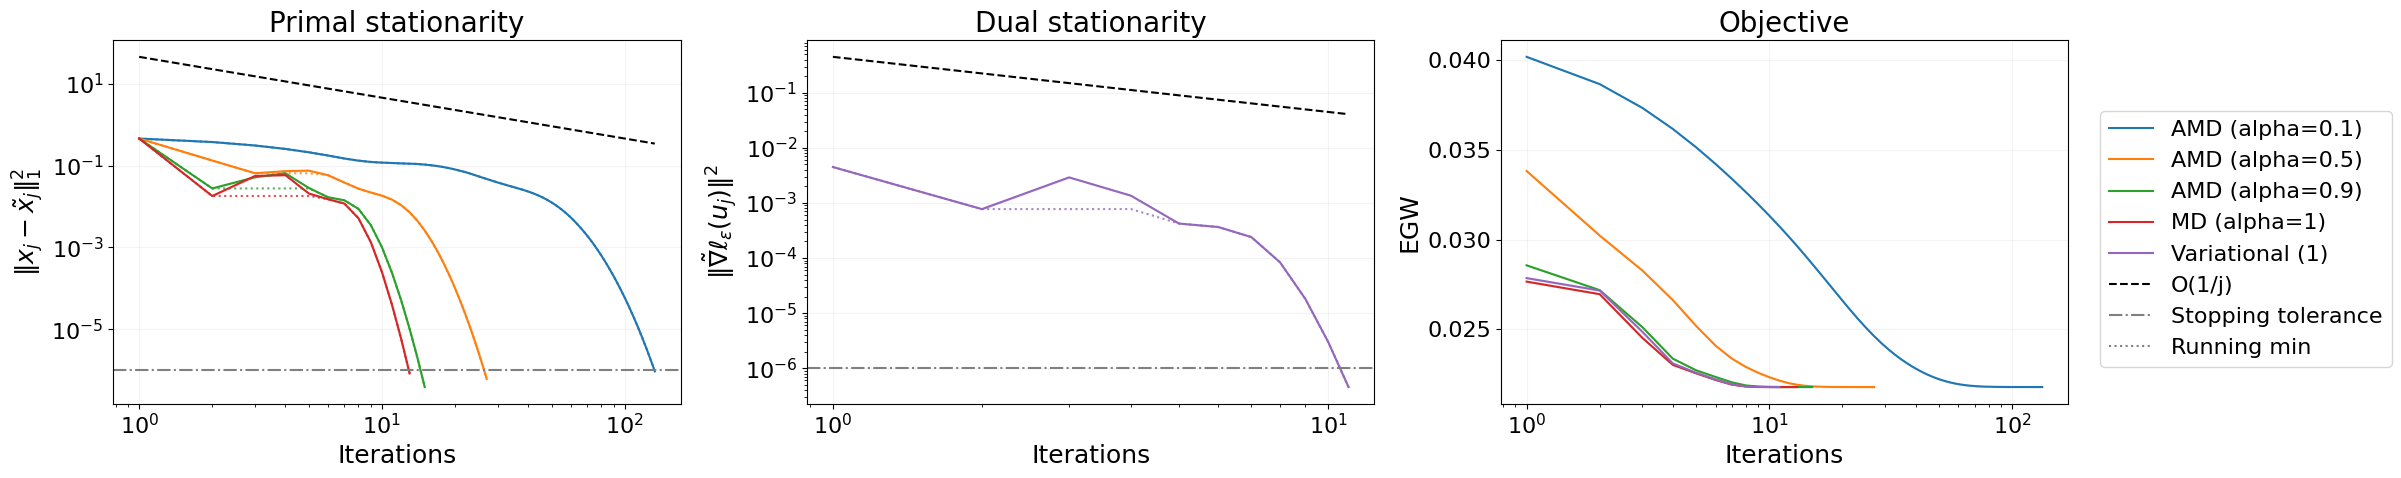

In [10]:
show_overlay(sphere_aggregate)

## Ring gaussians

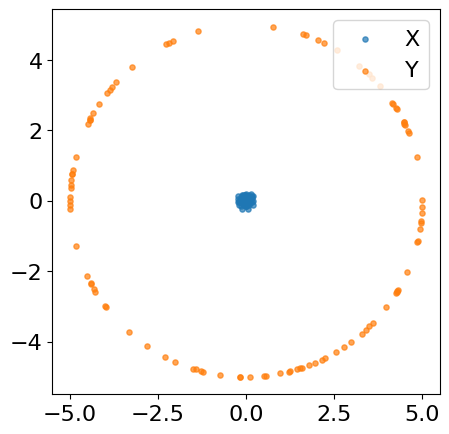

In [11]:
ring_gaussian_config = visualize_point_clouds("ring_gaussian")

In [12]:
ring_gaussian_aggregate = run_dataset(
    ring_gaussian_config,
    methods=["amd","dual_variational"],
    sinkhorn_method="sinkhorn_epsilon_scaling",
    num_seeds=1,
    algorithm_overrides={"max_iterations": 300},  # e.g. {"reg": 0.02, "max_iterations": 5000}
)

Running seed 0
  Running AMD (alpha=0.1)
Iteration 0, Stationarity: 1.827234690177622


Iteration 50, Stationarity: 0.015307011603028813
Iteration 100, Stationarity: 0.0007008982154895316
Iteration 150, Stationarity: 1.9552488230290788e-06
Iteration 156, Stationarity: 9.349661648557813e-07
  AMD (alpha=0.1): outer tolerance reached (8.66s)
  Running AMD (alpha=0.5)
Iteration 0, Stationarity: 1.827234690177622
Iteration 50, Stationarity: 0.069254099106919
Iteration 100, Stationarity: 0.07625062198743585
Iteration 145, Stationarity: 8.145984103691039e-07
  AMD (alpha=0.5): outer tolerance reached (7.31s)
  Running AMD (alpha=0.9)
Iteration 0, Stationarity: 1.827234690177622
Iteration 50, Stationarity: 2.1735094829791852
Iteration 100, Stationarity: 2.4462551684737774
Iteration 150, Stationarity: 2.446255169460162
Iteration 200, Stationarity: 2.446255169460579
Iteration 250, Stationarity: 2.4462551694602896
Iteration 299, Stationarity: 2.446255169460227
  AMD (alpha=0.9): iteration limit reached (16.62s)
  Running MD (alpha=1)
Iteration 0, Stationarity: 1.827234690177622
Ite

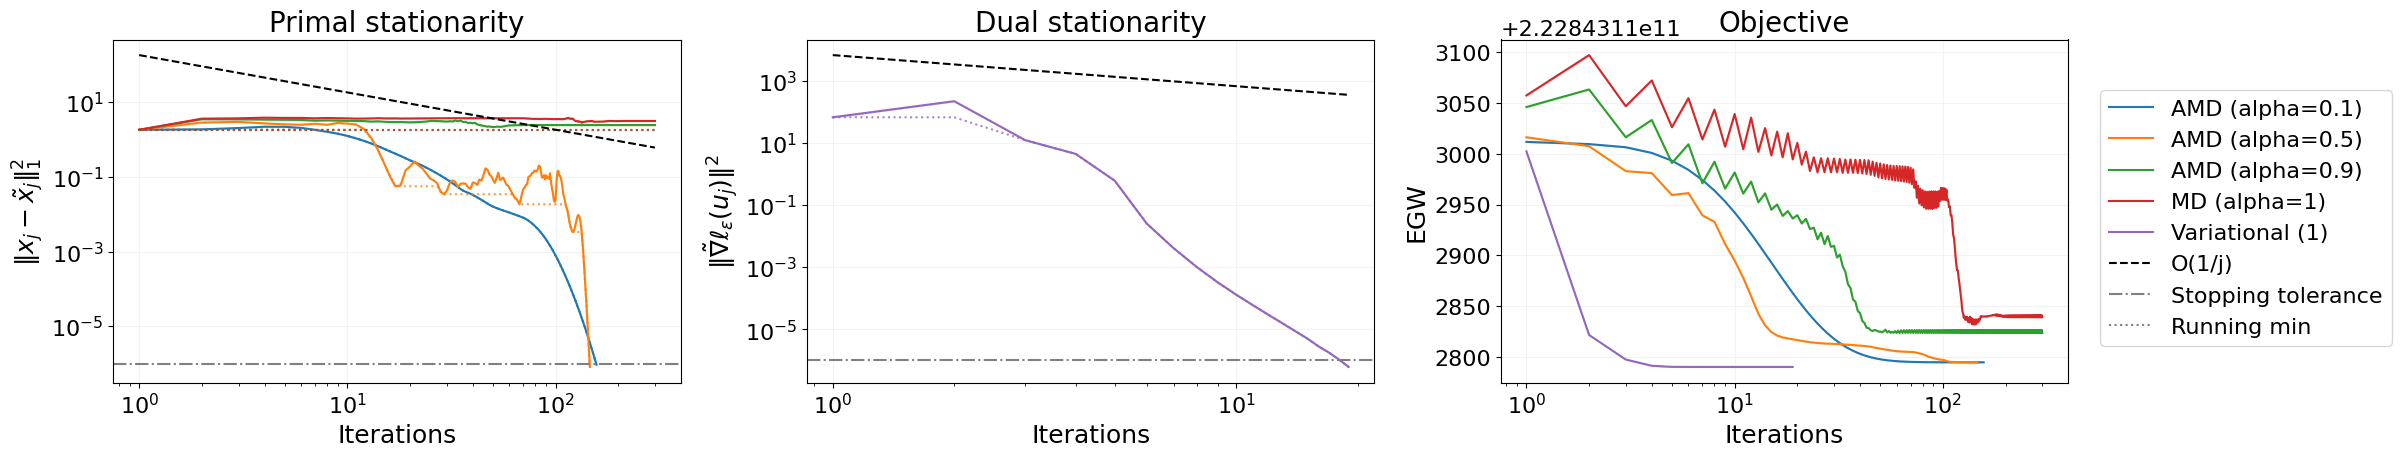

In [13]:
show_overlay(ring_gaussian_aggregate)

## Instability example

This section reconstructs the instability example from Houry et al 2026. The default power is set to 6 and the default $\epsilon=0.01$. Change these in the cell below to see the different settings presented in the manuscript.

### 1. Visualize the data

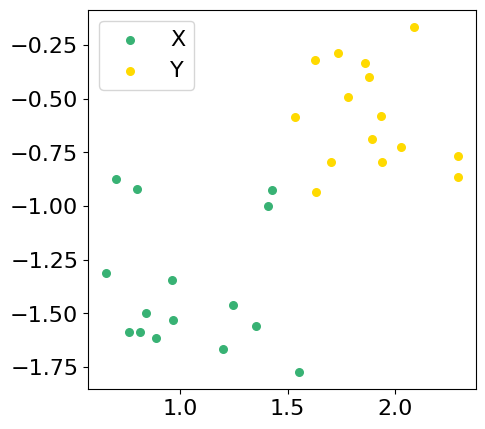

In [14]:
POWER = 6
REG = 0.01

x, y = example_point_clouds()
plt.figure(figsize=(5, 5))
plt.scatter(*x.T, s=30, c="#38b274", label="X")
plt.scatter(*y.T, s=30, c="#ffda00", label="Y")
plt.gca().set_aspect("equal", adjustable="box")
plt.legend()
plt.show()

### 2. Choose methods and run

In [15]:
methods = ["amd", "dual_variational"]  # choose any subset
overrides = {"reg": REG}  # e.g. {"reg": 0.02, "max_iterations": 500}

instability_example_config = load_config(REPO_ROOT / "configs" / "instability.yaml")
instability_example_config["experiment"]["seed"] = 0
instability_example_config["data"]["cost_power"] = POWER
algorithm = instability_example_config["algorithm"]
algorithm["methods"] = methods
algorithm.update(overrides)
K = int(algorithm["max_iterations"])
OUTER_TOL = float(algorithm.get("outer_tol", algorithm.get("tol", 1e-6)))

clouds, Cx, Cy, P_init, offset = prepare_experiment(instability_example_config)
jobs = selected_jobs(algorithm)
saving = {"save_full_history": True}
results, arrays = run_methods_on_problem(
    Cx, Cy, clouds["wtx"], clouds["wty"], P_init, offset,
    jobs, K, algorithm["reg"], OUTER_TOL, algorithm["factorization"], algorithm, saving,
    extra_arrays=dict(x=clouds["x"], y=clouds["y"], wtx=clouds["wtx"], wty=clouds["wty"]),
)
for result in results:
    print(f"  {result['label']}: {result['status']}")

  Running AMD (alpha=0.1)
Iteration 0, Stationarity: 0.38905853078230895
Iteration 50, Stationarity: 0.0006383584080536254
Iteration 87, Stationarity: 9.307570202869482e-07
  AMD (alpha=0.1): outer tolerance reached (6.69s)
  Running AMD (alpha=0.5)
Iteration 0, Stationarity: 0.38905853078230895
Iteration 16, Stationarity: 8.324734005693416e-07
  AMD (alpha=0.5): outer tolerance reached (1.31s)
  Running AMD (alpha=0.9)
Iteration 0, Stationarity: 0.38905853078230895
Iteration 50, Stationarity: 0.8054718286292593
Iteration 100, Stationarity: 0.8054718286292611
Iteration 150, Stationarity: 0.8054718286292626
Iteration 200, Stationarity: 0.805471828629261
Iteration 250, Stationarity: 0.8054718286292614
Iteration 299, Stationarity: 0.805471828629261
  AMD (alpha=0.9): iteration limit reached (16.32s)
  Running MD (alpha=1)
Iteration 0, Stationarity: 0.38905853078230895
Iteration 50, Stationarity: 1.196658092234355
Iteration 100, Stationarity: 1.196658092234354
Iteration 150, Stationarity: 

### 3. Diagnostic plots


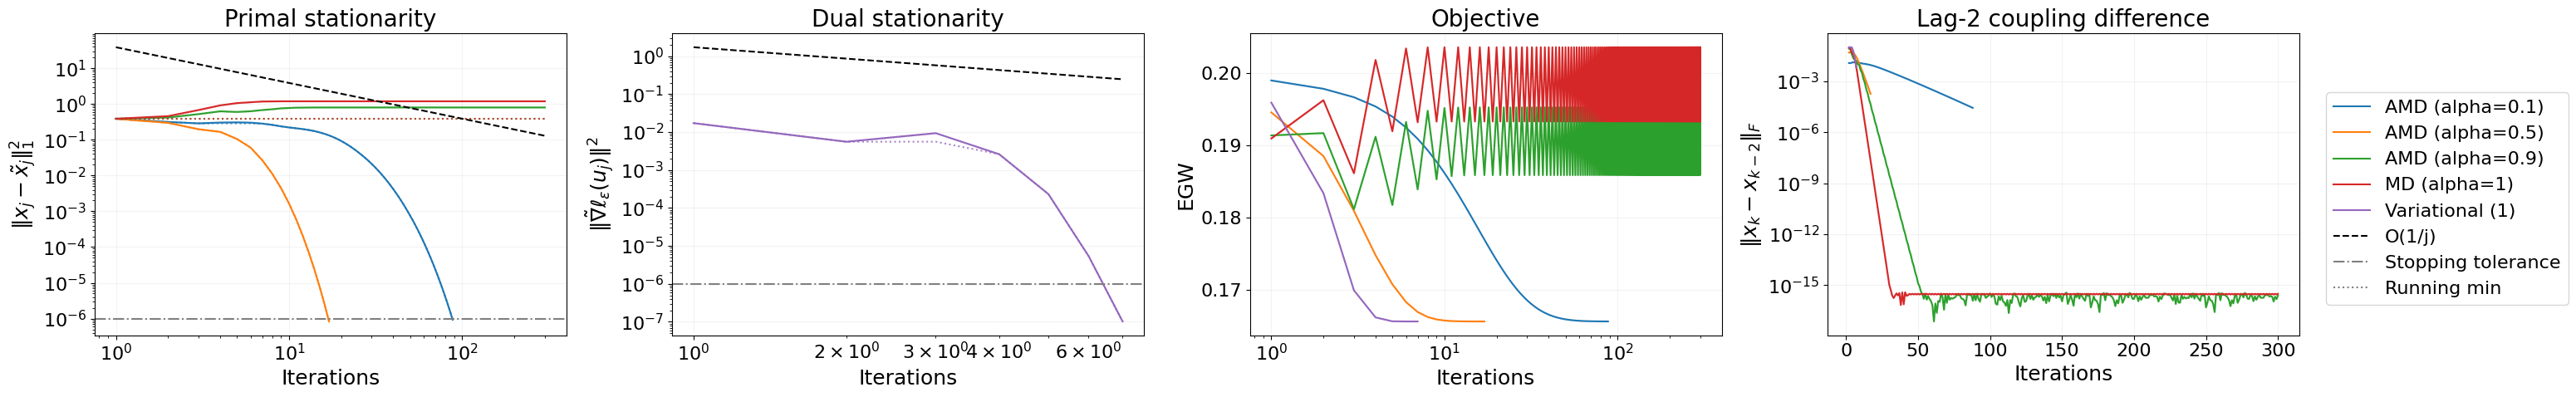

In [16]:
for result in results:
    key = result["method"].replace(".", "p")
    couplings = arrays.get(f"couplings_{key}")
    result["lag2_frobenius"] = (
        lag2_frobenius(couplings).tolist() if couplings is not None and len(couplings) >= 3 else []
    )

aggregate, _aggregate_arrays = aggregate_runs([{"seed": 0, "results": results}], [0])
show_overlay(aggregate)

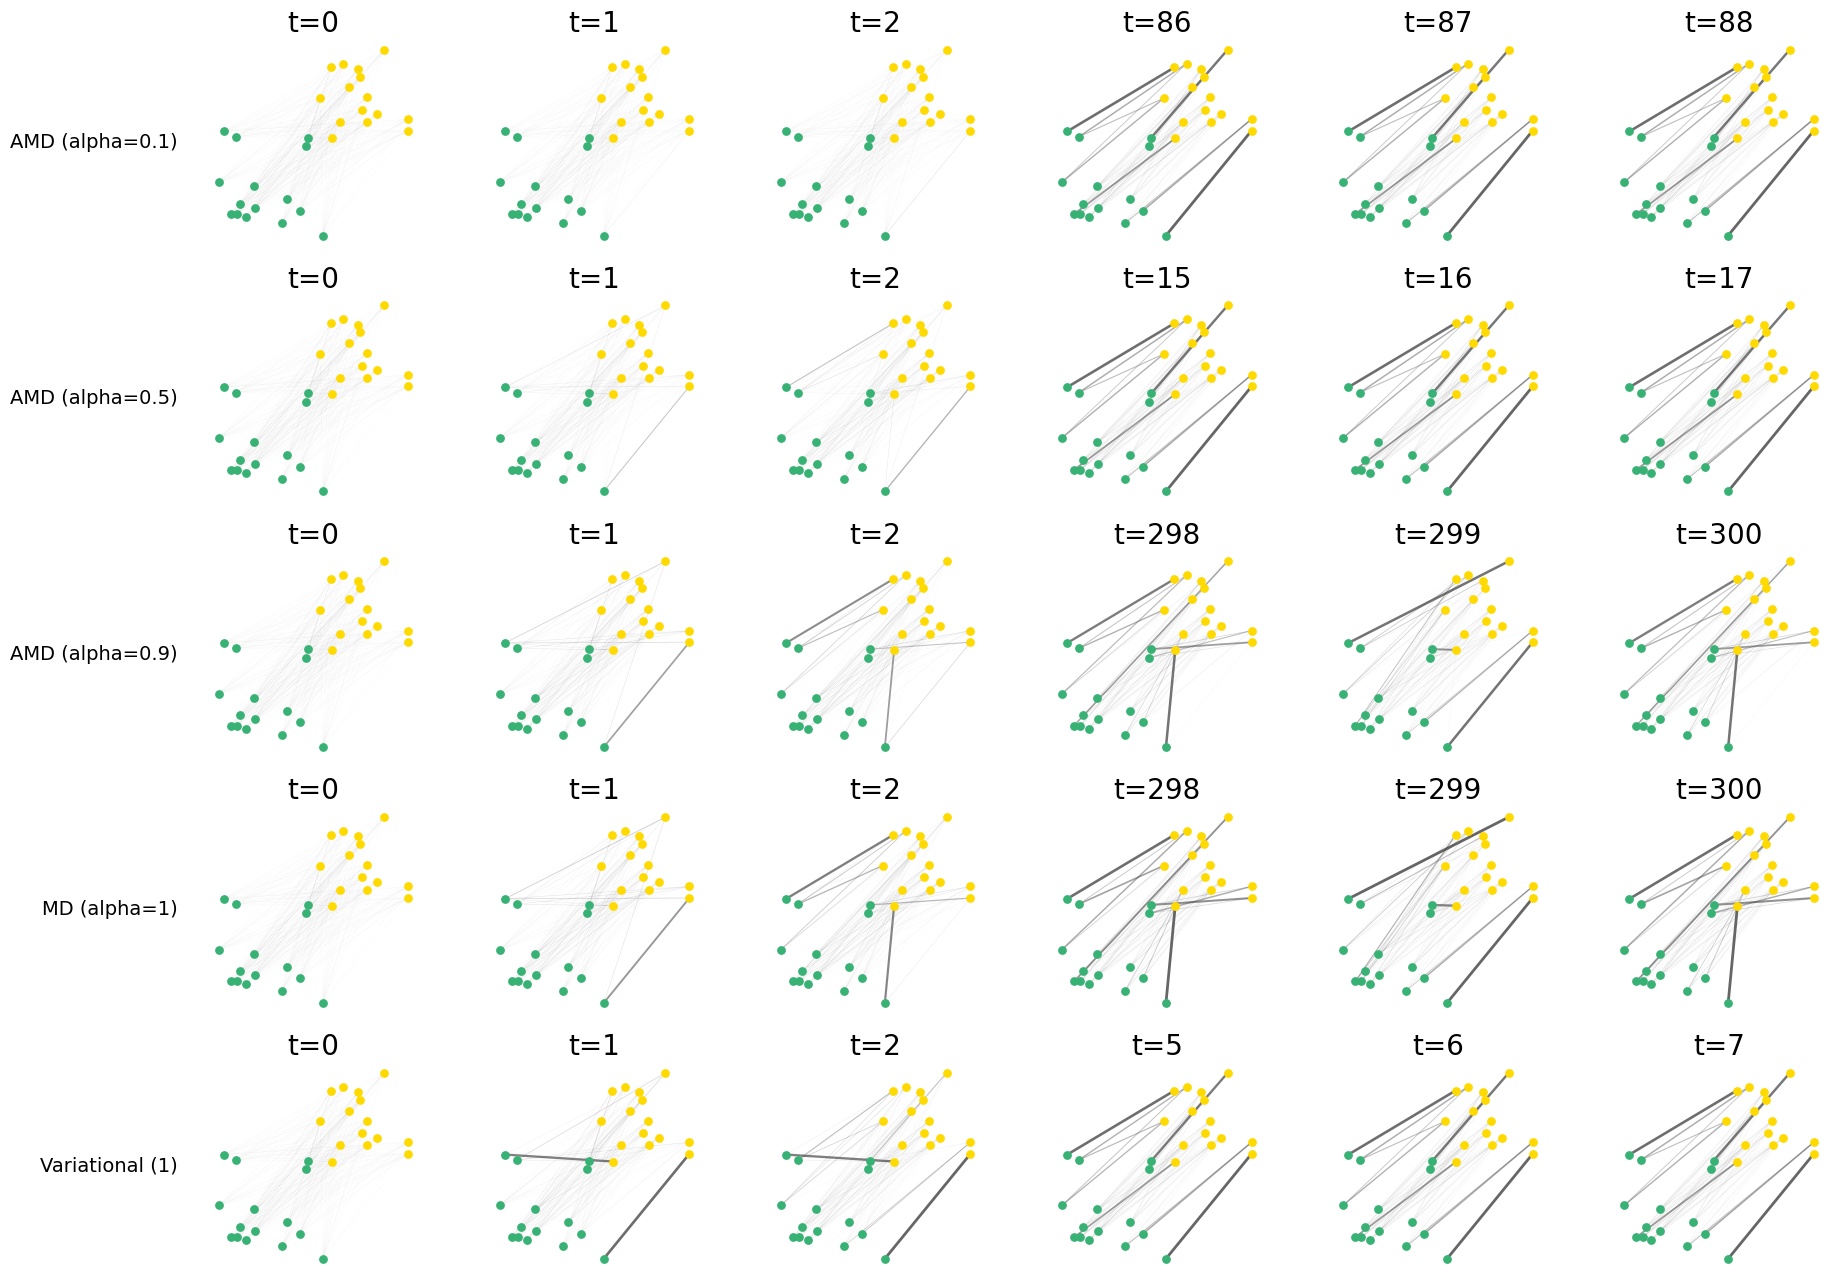

In [17]:
show_transport_snapshots(results, arrays, clouds["x"], clouds["y"])